<a href="https://colab.research.google.com/github/nnroja/sms-spam-detection/blob/main/SMS_Spam_SVM_Updated.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# SMS Spam Classification using SVM

Classifies SMS messages as **spam** or **ham** (legitimate) using TF-IDF features and a linear Support Vector Machine.

Dataset: [SMS Spam Collection (Kaggle)](https://www.kaggle.com/datasets/uciml/sms-spam-collection-dataset)

**Workflow:** load data → remove duplicates → EDA → text cleaning → stratified split → baseline SVM → grid search (tuned for spam F1) → held-out test evaluation → error analysis → save model → predict new messages.

In [1]:
# Install (if needed)
!pip -q install wordcloud nltk scikit-learn seaborn joblib

In [2]:
import re, string, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import nltk, joblib

from wordcloud import WordCloud
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score, StratifiedKFold
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC
from sklearn.pipeline import Pipeline
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             classification_report, ConfusionMatrixDisplay,
                             roc_curve, roc_auc_score)

warnings.filterwarnings("ignore", category=FutureWarning)
nltk.download('stopwords', quiet=True)
nltk.download('wordnet', quiet=True)

RANDOM_STATE = 42

## Load Dataset
Download `spam.csv` from Kaggle. In Google Colab you'll be prompted to upload it; when running locally, set `DATA_PATH` to the file's location.

In [3]:
DATA_PATH = "SMS.csv"   # change to "spam.csv" or your own path if needed

import os
if not os.path.exists(DATA_PATH):
    try:
        from google.colab import files          # only available in Colab
        uploaded = files.upload()
        DATA_PATH = next(iter(uploaded))
    except ImportError:
        raise FileNotFoundError(f"{DATA_PATH} not found. Download the dataset and set DATA_PATH.")

df = pd.read_csv(DATA_PATH, encoding="latin-1")
df = df[['v1', 'v2']]
df.columns = ['label', 'message']
df.head()

Saving archive.zip to archive.zip


,label,message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


## Data Quality Check

In [4]:
print("Shape:", df.shape)
print("Missing values:\n", df.isnull().sum())
print("Duplicates:", df.duplicated().sum())
print(df['label'].value_counts())

# Remove duplicates BEFORE EDA/splitting so identical messages can't leak across train/test
df = df.drop_duplicates().reset_index(drop=True)
print("\nShape after dropping duplicates:", df.shape)
print(df['label'].value_counts(normalize=True).round(3))

Shape: (5572, 2)
Missing values:
 label      0
message    0
dtype: int64
Duplicates: 403
label
ham     4825
spam     747
Name: count, dtype: int64

Shape after dropping duplicates: (5169, 2)
label
ham     0.874
spam    0.126
Name: proportion, dtype: float64


## Exploratory Data Analysis

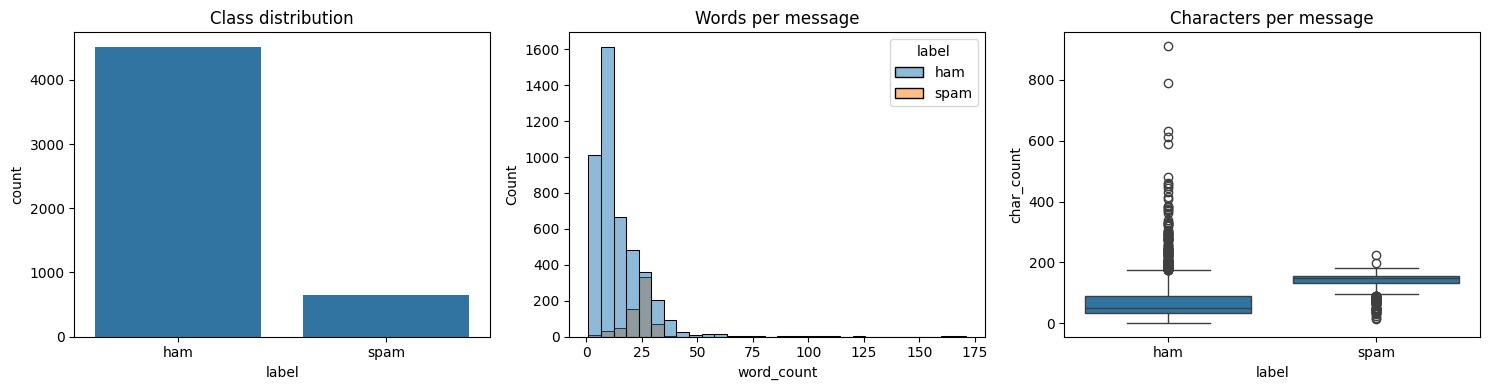

,char_count,word_count
label,,
ham,70.5,14.1
spam,137.9,23.7


In [5]:
df['char_count'] = df['message'].str.len()
df['word_count'] = df['message'].str.split().str.len()

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
sns.countplot(data=df, x='label', ax=ax[0]);                        ax[0].set_title("Class distribution")
sns.histplot(data=df, x='word_count', hue='label', bins=30, ax=ax[1]); ax[1].set_title("Words per message")
sns.boxplot(data=df, x='label', y='char_count', ax=ax[2]);          ax[2].set_title("Characters per message")
plt.tight_layout(); plt.show()

df.groupby('label')[['char_count', 'word_count']].mean().round(1)

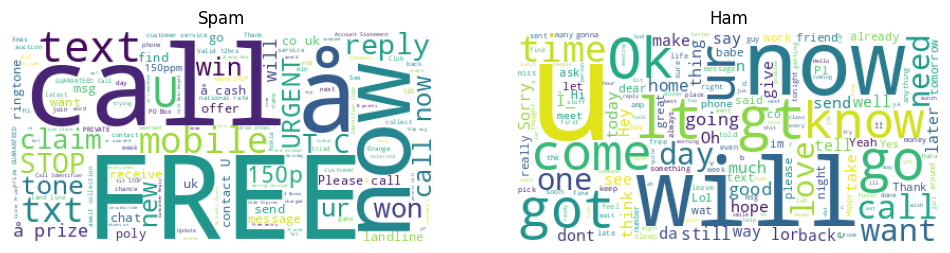

In [6]:
spam = ' '.join(df[df.label == 'spam'].message)
ham  = ' '.join(df[df.label == 'ham'].message)

plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.imshow(WordCloud(background_color='white').generate(spam)); plt.axis('off'); plt.title("Spam")
plt.subplot(1, 2, 2)
plt.imshow(WordCloud(background_color='white').generate(ham));  plt.axis('off'); plt.title("Ham")
plt.show()

## Preprocessing
URLs, e-mail addresses, phone-number-like digit strings and currency symbols are strong spam signals, so instead of deleting them they are replaced with placeholder tokens (`urltoken`, `emailtoken`, `numtoken`, `currencytoken`). Remaining punctuation is removed, stopwords are dropped and words are lemmatized.

In [7]:
stop_words = set(stopwords.words('english'))
lemm = WordNetLemmatizer()
PUNCT_TABLE = str.maketrans('', '', string.punctuation)

def clean_text(text):
    text = text.lower()
    text = re.sub(r'http\S+|www\S+', ' urltoken ', text)     # URLs
    text = re.sub(r'\S+@\S+', ' emailtoken ', text)          # e-mail addresses
    text = re.sub(r'[£$€]', ' currencytoken ', text)          # currency symbols
    text = re.sub(r'\d+', ' numtoken ', text)                # numbers
    text = text.translate(PUNCT_TABLE)                       # punctuation
    tokens = [lemm.lemmatize(w) for w in text.split() if w not in stop_words]
    return ' '.join(tokens)

df['clean_message'] = df['message'].apply(clean_text)
df['label'] = df['label'].map({'ham': 0, 'spam': 1})

df[['message', 'clean_message', 'label']].head()

,message,clean_message,label
0,"Go until jurong point, crazy.. Available only ...",go jurong point crazy available bugis n great ...,0
1,Ok lar... Joking wif u oni...,ok lar joking wif u oni,0
2,Free entry in 2 a wkly comp to win FA Cup fina...,free entry numtoken wkly comp win fa cup final...,1
3,U dun say so early hor... U c already then say...,u dun say early hor u c already say,0
4,"Nah I don't think he goes to usf, he lives aro...",nah dont think go usf life around though,0


## Train/Test Split

In [8]:
X = df['clean_message']
y = df['label']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)
print("Train:", X_train.shape, " Test:", X_test.shape)
print("Spam share  train: %.3f  test: %.3f" % (y_train.mean(), y_test.mean()))

Train: (4135,)  Test: (1034,)
Spam share  train: 0.126  test: 0.127


## Baseline SVM

In [9]:
pipeline = Pipeline([
    ('tfidf', TfidfVectorizer(max_features=5000, ngram_range=(1, 2))),
    ('svm', LinearSVC(random_state=RANDOM_STATE))
])

pipeline.fit(X_train, y_train)
base_pred = pipeline.predict(X_test)

print("Accuracy :", round(accuracy_score(y_test, base_pred), 4))
print("Precision:", round(precision_score(y_test, base_pred), 4))
print("Recall   :", round(recall_score(y_test, base_pred), 4))
print("F1       :", round(f1_score(y_test, base_pred), 4))
print(classification_report(y_test, base_pred, target_names=['ham', 'spam']))

Accuracy : 0.9845
Precision: 0.96
Recall   : 0.916
F1       : 0.9375
              precision    recall  f1-score   support

         ham       0.99      0.99      0.99       903
        spam       0.96      0.92      0.94       131

    accuracy                           0.98      1034
   macro avg       0.97      0.96      0.96      1034
weighted avg       0.98      0.98      0.98      1034



## Hyperparameter Tuning
The classes are imbalanced (~13% spam), and plain accuracy is dominated by the ham class. The grid search therefore optimises **F1 for the spam class** and also tries `class_weight='balanced'`, which usually improves spam recall.

In [10]:
param_grid = {
    'tfidf__ngram_range': [(1, 1), (1, 2)],
    'tfidf__max_features': [5000, None],
    'tfidf__sublinear_tf': [True],
    'svm__C': [0.1, 0.5, 1, 5, 10],
    'svm__class_weight': [None, 'balanced'],
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
grid = GridSearchCV(pipeline, param_grid, cv=cv, scoring='f1', n_jobs=-1)
grid.fit(X_train, y_train)

print("Best parameters:", grid.best_params_)
print("Best CV F1 (train only): %.4f" % grid.best_score_)

Best parameters: {'svm__C': 10, 'svm__class_weight': 'balanced', 'tfidf__max_features': None, 'tfidf__ngram_range': (1, 2), 'tfidf__sublinear_tf': True}
Best CV F1 (train only): 0.9419


## Final Evaluation on the Held-out Test Set

Accuracy : 0.9836
Precision: 0.9524
Recall   : 0.916
F1       : 0.9339
ROC AUC  : 0.9961
              precision    recall  f1-score   support

         ham       0.99      0.99      0.99       903
        spam       0.95      0.92      0.93       131

    accuracy                           0.98      1034
   macro avg       0.97      0.95      0.96      1034
weighted avg       0.98      0.98      0.98      1034



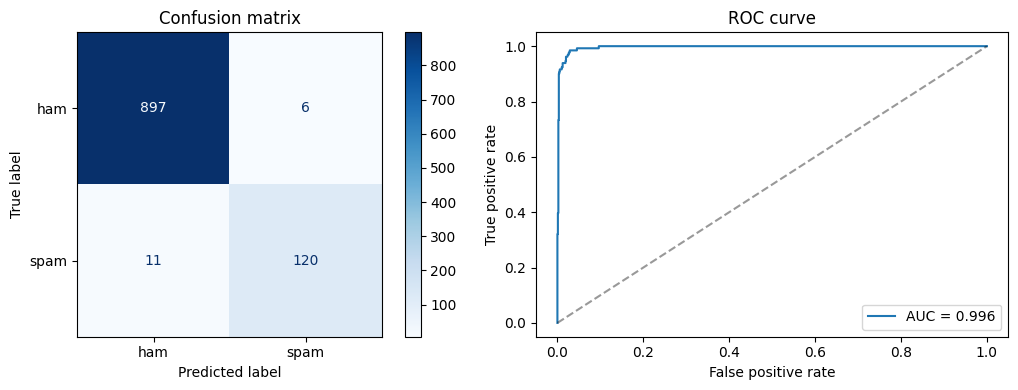

In [11]:
model = grid.best_estimator_
pred = model.predict(X_test)
scores = model.decision_function(X_test)

print("Accuracy :", round(accuracy_score(y_test, pred), 4))
print("Precision:", round(precision_score(y_test, pred), 4))
print("Recall   :", round(recall_score(y_test, pred), 4))
print("F1       :", round(f1_score(y_test, pred), 4))
print("ROC AUC  :", round(roc_auc_score(y_test, scores), 4))
print(classification_report(y_test, pred, target_names=['ham', 'spam']))

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ConfusionMatrixDisplay.from_predictions(y_test, pred, display_labels=['ham', 'spam'],
                                        cmap='Blues', ax=ax[0])
ax[0].set_title("Confusion matrix")
fpr, tpr, _ = roc_curve(y_test, scores)
ax[1].plot(fpr, tpr, label=f"AUC = {roc_auc_score(y_test, scores):.3f}")
ax[1].plot([0, 1], [0, 1], 'k--', alpha=.4)
ax[1].set_xlabel("False positive rate"); ax[1].set_ylabel("True positive rate")
ax[1].set_title("ROC curve"); ax[1].legend()
plt.tight_layout(); plt.show()

## Cross Validation
Cross-validation is run on the **training set only**, so the test set stays untouched. (Note: the grid search above already selected hyperparameters on this data, so treat this as a stability check rather than an unbiased estimate; the test-set results above are the unbiased ones.)

In [12]:
cv_scores = cross_val_score(model, X_train, y_train, cv=cv, scoring='f1')
print("F1 per fold:", np.round(cv_scores, 4))
print("Mean F1: %.4f  (+/- %.4f)" % (cv_scores.mean(), cv_scores.std()))

F1 per fold: [0.9604 0.9216 0.9515 0.9194 0.9565]
Mean F1: 0.9419  (+/- 0.0177)


## Error Analysis

In [13]:
errors = pd.DataFrame({'message': df.loc[X_test.index, 'message'],
                       'actual': y_test, 'predicted': pred})
pd.set_option('display.max_colwidth', 120)

print("False negatives (spam predicted as ham):")
display(errors[(errors.actual == 1) & (errors.predicted == 0)].head(10))
print("False positives (ham predicted as spam):")
display(errors[(errors.actual == 0) & (errors.predicted == 1)].head(10))

False negatives (spam predicted as ham):


,message,actual,predicted
520,You will recieve your tone within the next 24hrs. For Terms and conditions please see Channel U Teletext Pg 750,1,0
3947,Missed call alert. These numbers called but left no message. 07008009200,1,0
660,SMS. ac sun0819 posts HELLO:\You seem cool,1,0
2302,Babe: U want me dont u baby! Im nasty and have a thing 4 filthyguys. Fancy a rude time with a sexy bitch. How about ...,1,0
3888,"In The Simpsons Movie released in July 2007 name the band that died at the start of the film? A-Green Day, B-Blue Da...",1,0
3330,"Xmas & New Years Eve tickets are now on sale from the club, during the day from 10am till 8pm, and on Thurs, Fri & S...",1,0
5062,"Latest News! Police station toilet stolen, cops have nothing to go on!",1,0
4183,Want explicit SEX in 30 secs? Ring 02073162414 now! Costs 20p/min,1,0
1812,Would you like to see my XXX pics they are so hot they were nearly banned in the uk!,1,0
3741,ringtoneking 84484,1,0


False positives (ham predicted as spam):


,message,actual,predicted
1793,K.:)you are the only girl waiting in reception ah?,0,1
151,Ok... Ur typical reply...,0,1
4806,K k:) sms chat with me.,0,1
2888,Your bill at 3 is å£33.65 so thats not bad!,0,1
3586,Yep then is fine 7.30 or 8.30 for ice age.,0,1
1252,"Hey...Great deal...Farm tour 9am to 5pm $95/pax, $50 deposit by 16 May",0,1


In [14]:
# Most influential words for each class
feature_names = model.named_steps['tfidf'].get_feature_names_out()
coefs = model.named_steps['svm'].coef_[0]
top = pd.DataFrame({
    'top spam words': feature_names[np.argsort(coefs)[-15:][::-1]],
    'top ham words':  feature_names[np.argsort(coefs)[:15]],
})
top

,top spam words,top ham words
0,call numtoken,ltgt
1,urltoken,im free
2,numtoken numtoken,get ok
3,currencytoken,liked new
4,service,free call
5,mobile,ill
6,txt,liked
7,free,ok
8,currencytoken numtoken,call please
9,reply,it


## Save Model & Prediction Function

In [15]:
joblib.dump(model, "spam_svm_model.joblib")   # reload later with joblib.load(...)

def predict_sms(text):
    pred = model.predict([clean_text(text)])[0]
    return "Spam" if pred == 1 else "Ham"

print(predict_sms("Congratulations! You have won a free iPhone. Click here now."))
print(predict_sms("Hi, are we meeting tomorrow at 3 PM?"))

Spam
Ham
